# Group Project: Predicting Short-Term Stock Prices for Move Tickers

**Group work (Group 11)** · Breda University of Applied Sciences, ADS&AI Year 1 Block D (2024-25)

This notebook contains the group's machine learning work for the client **Move Tickers**. It uses minute-level stock data for **Apple (AAPL), Amazon (AMZN) and Alphabet (GOOG)**, joined with NASDAQ-100 index values, the VIX and macroeconomic indicators. The data comes from the group's PostgreSQL data warehouse.

> **Status:** this is the notebook as it was at the end of the block. Data loading, preprocessing, feature engineering and a linear regression baseline are complete. The LSTM model, backtesting, hyperparameter tuning and deployment were started but not finished (see *Next steps* at the end).

## 🔍 Step 1: Problem Statement

Move Tickers wants data-driven signals that help traders react to short-term market moves. In this notebook we try to predict the **next-minute high price** of a stock from its recent price behaviour, market-wide indicators (NASDAQ-100 index, VIX) and macroeconomic context (GDP growth, CPI inflation). A reliable short-term forecast could support alerts or trading signals on the Move Tickers platform.

## 🗄️ Step 2: Load and Explore Data

The data is loaded from the `model_input_data` table in the group's PostgreSQL warehouse using SQLAlchemy. Database credentials are read from environment variables (see `.env.example` in the repository root) so no passwords are stored in the notebook.

In [1]:
# import all the libraries here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sqlalchemy import create_engine
from sqlalchemy.exc import SQLAlchemyError
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler

In [ ]:
import os

# Database credentials come from environment variables (see .env.example)
db_params = {
    "host": os.getenv("DB_HOST"),
    "port": os.getenv("DB_PORT", "5432"),
    "database": os.getenv("DB_NAME"),
    "user": os.getenv("DB_USER"),
    "password": os.getenv("DB_PASSWORD"),
}

# Build connection string
db_url = (
    f"postgresql+psycopg2://{db_params['user']}:{db_params['password']}"
    f"@{db_params['host']}:{db_params['port']}/{db_params['database']}"
)

# Connect, read the model input table and save a local copy
try:
    engine = create_engine(db_url)
    with engine.connect() as connection:
        df = pd.read_sql("SELECT * FROM model_input_data;", connection)
        df.to_csv("../data/model_input_data.csv", index=False)
        print("Data loaded and saved to CSV successfully.")
except SQLAlchemyError as e:
    print("Database connection or query failed:")
    print(str(e))
except Exception as e:
    print("Unexpected error:")
    print(str(e))


📌 **Note:** the cell above only needs to run once. After that, the data is read from the local CSV file, so the database server is not needed (the CSV is ~69 MB and is not included in this repository).

In [2]:
df = pd.read_csv("../data/model_input_data.csv", parse_dates=["date_value"], index_col='date_value')
df = df.sort_index()
df.head()

,company_prefix,open_value,high_value,low_value,close_value,volume,transactions,return_pct,intraday_volatility,momentum_hl,range_pct_hl,index_open,index_close,stock_market_volatility_vix_index,gdp_growth,inflation_cpi,return_lag_5
date_value,,,,,,,,,,,,,,,,,
2023-01-09 09:00:00,GOOG,88.08,88.17,88.08,88.16,1684.0,55,0.000908,0.001022,0.09,0.001022,11133.070312,11108.450195,21.97,NaN,NaN,NaN
2023-01-09 09:00:00,AMZN,86.51,86.51,86.38,86.40,3721.0,59,-0.001272,0.001503,0.13,0.001503,11133.070312,11108.450195,21.97,NaN,NaN,NaN
2023-01-09 09:00:00,AAPL,129.60,130.30,129.60,129.89,2312.0,85,0.002238,0.005401,0.70,0.005401,11133.070312,11108.450195,21.97,NaN,NaN,NaN
2023-01-09 09:01:00,AMZN,86.29,86.29,86.29,86.29,749.0,16,0.000000,0.000000,0.00,0.000000,11133.070312,11108.450195,21.97,NaN,NaN,NaN
2023-01-09 09:01:00,AAPL,129.80,129.80,129.68,129.70,6206.0,74,-0.000770,0.000924,0.12,0.000924,11133.070312,11108.450195,21.97,NaN,NaN,NaN


In [3]:
print("\nCurrent index frequency:", df.index.freq)


Current index frequency: None


## 📊 Step 3: Preprocessing

Exploratory analysis, handling missing values, feature engineering and scaling.

**EDA**

In [4]:
print(df.shape)
print(df['company_prefix'].unique())
df.describe()

(353644, 17)
['AAPL' 'AMZN' 'GOOG']


,open_value,high_value,low_value,close_value,volume,transactions,return_pct,intraday_volatility,momentum_hl,range_pct_hl,index_open,index_close,stock_market_volatility_vix_index,gdp_growth,inflation_cpi,return_lag_5
count,353644.000000,353644.000000,353644.000000,353644.000000,3.536440e+05,353644.000000,3.536440e+05,353644.000000,353644.000000,353644.000000,352838.000000,352838.000000,352940.000000,1313.000000,1313.000000,3.536290e+05
mean,161.548029,161.597744,161.496846,161.547848,5.016636e+04,599.918144,-9.273659e-07,0.000648,0.100898,0.000648,16642.119074,16643.310222,16.110123,29571.355334,314.771191,-9.297916e-07
std,36.880325,36.884660,36.875699,36.880439,1.285033e+05,916.634344,6.998060e-04,0.000960,0.152643,0.000960,2852.643520,2831.064631,3.062685,159.387622,0.977862,6.998190e-04
min,86.290000,86.290000,86.290000,86.290000,1.000000e+02,1.000000,-5.117043e-02,0.000000,0.000000,0.000000,11069.049805,11108.450195,11.860000,29374.914000,313.566000,-5.117043e-02
25%,134.220000,134.260000,134.170000,134.220000,1.350000e+03,29.000000,-2.009052e-04,0.000155,0.020000,0.000155,14762.009766,14715.809570,13.600000,29374.914000,313.566000,-2.009127e-04
50%,167.240000,167.300000,167.190000,167.234700,2.223950e+04,347.000000,0.000000e+00,0.000480,0.075800,0.000480,16775.099609,16811.849609,15.420000,29700.580000,315.564000,0.000000e+00
75%,184.480025,184.540000,184.427975,184.489775,6.337600e+04,796.000000,2.044273e-04,0.000847,0.130000,0.000847,19450.570312,19059.490234,17.890000,29700.580000,315.564000,2.044321e-04
max,259.910000,260.100000,259.710000,259.929900,1.633845e+07,38494.000000,6.744775e-02,0.124367,22.120000,0.124367,21733.980469,21797.650391,26.520000,29700.580000,315.564000,6.744775e-02


In [24]:
dups = df.index.duplicated().sum()
print(f"Duplicate timestamps: {dups}")

Duplicate timestamps: 195213


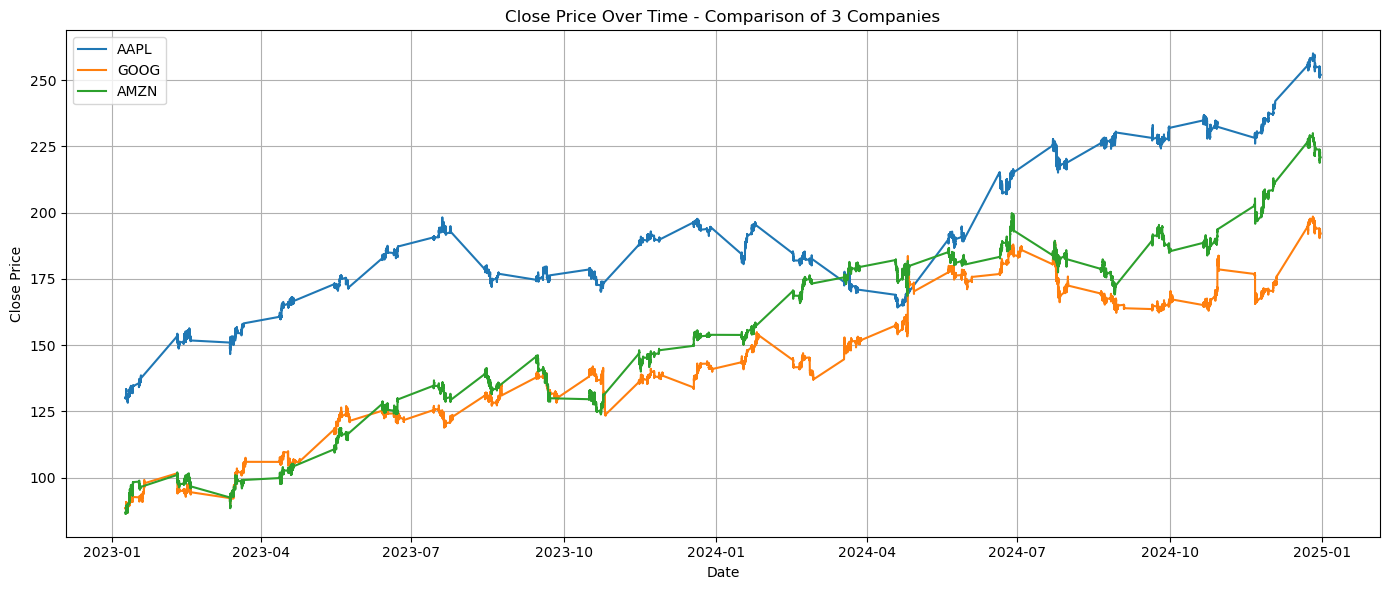

In [18]:
# Select the first 3 companies
selected_companies = df['company_prefix'].unique()[:3]

# Create the plot
plt.figure(figsize=(14, 6))
for company in selected_companies:
    df_subset = df[df['company_prefix'] == company]
    plt.plot(df_subset.index, df_subset['high_value'], label=company)

plt.title('Close Price Over Time - Comparison of 3 Companies')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

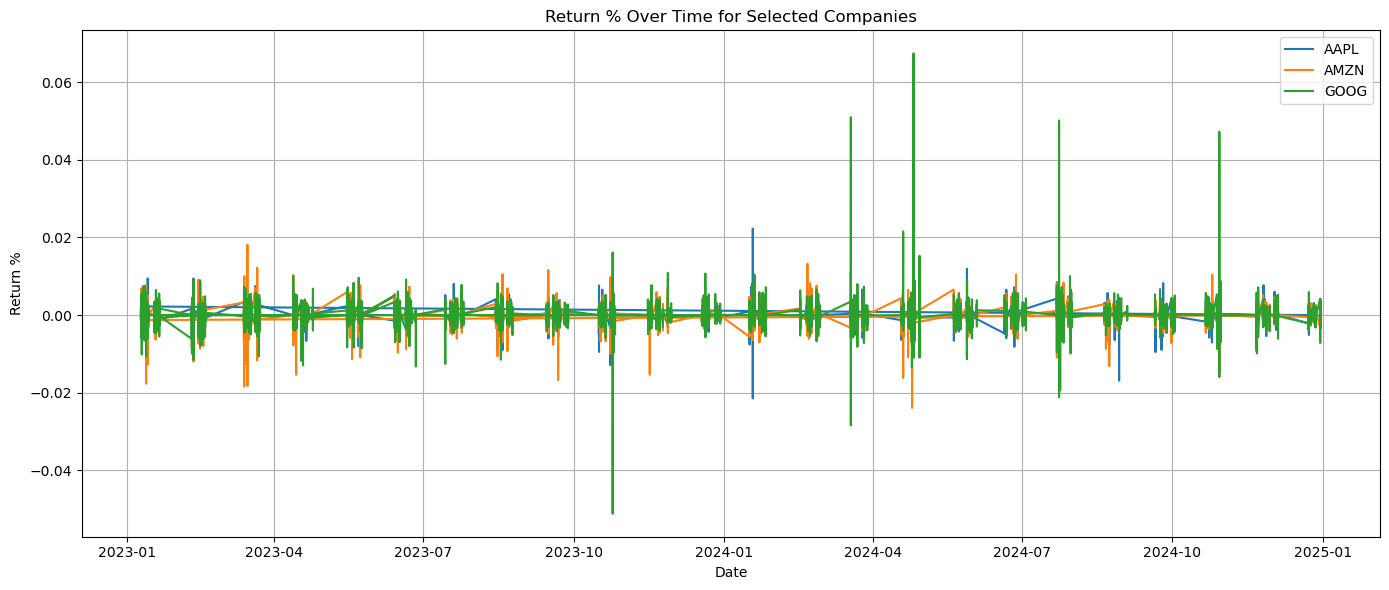

In [8]:
selected_companies = df['company_prefix'].unique()[:3]

plt.figure(figsize=(14, 6))
for company in selected_companies:
    df_subset = df[df['company_prefix'] == company]
    plt.plot(df_subset.index, df_subset['return_pct'], label=company)

plt.title('Return % Over Time for Selected Companies')
plt.xlabel('Date')
plt.ylabel('Return %')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

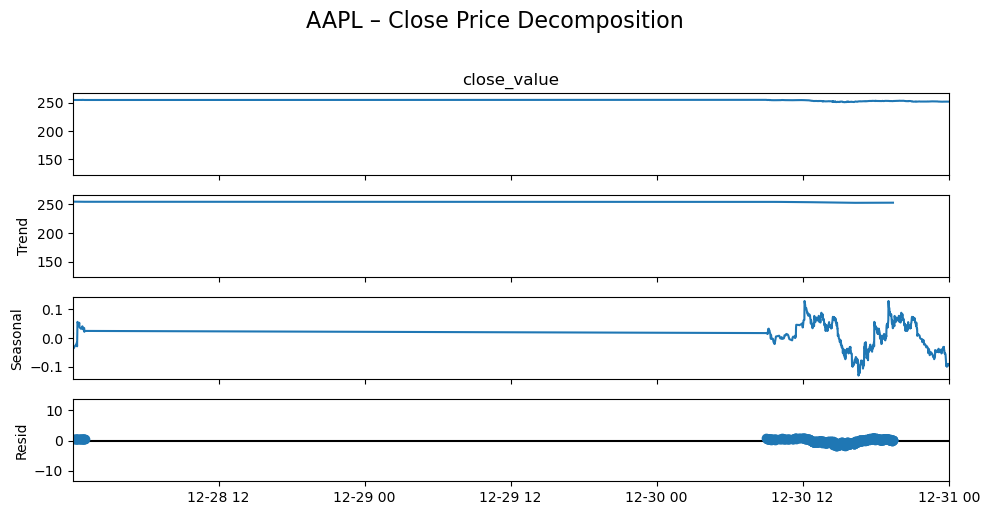

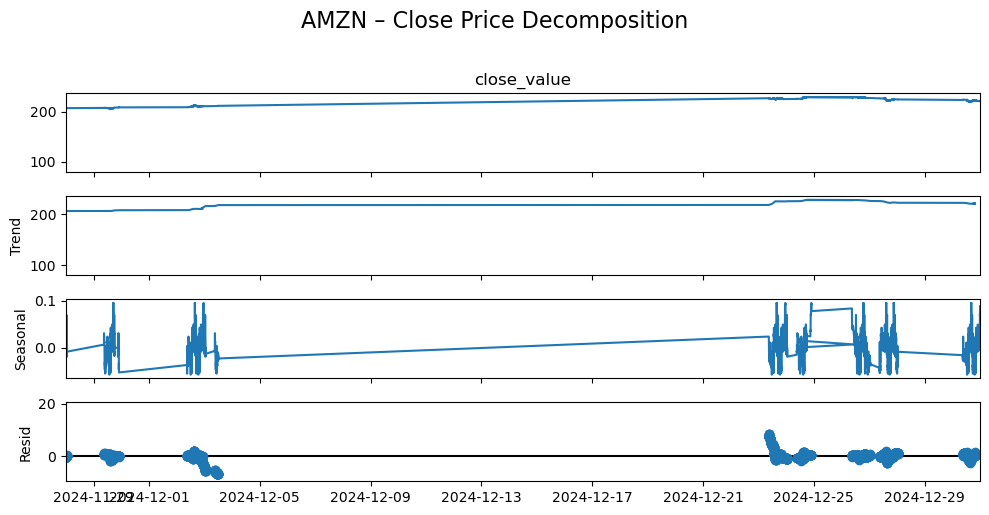

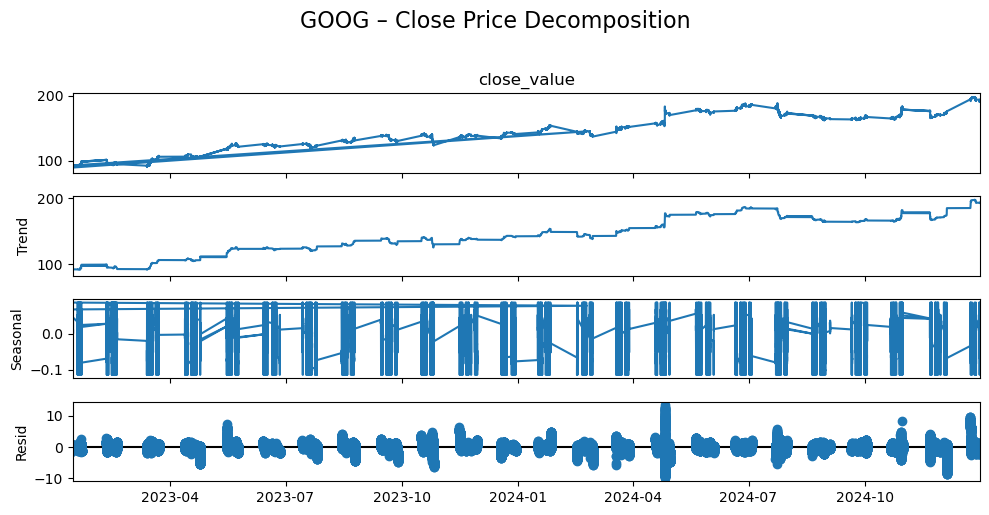

In [9]:
for i in range(0, 3):
    company = df['company_prefix'].unique()[i]
    df_company = df[df['company_prefix'] == company]

    ts = df_company['close_value']

    ts = ts.dropna()

    decomposition = seasonal_decompose(ts, model='additive', period=390)  

    fig = decomposition.plot()
    fig.set_size_inches(10, 5)
    plt.suptitle(f'{company} – Close Price Decomposition', fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

**Handling missing values**

In [10]:
missing_counts = df.isnull().sum()
missing_counts

company_prefix                            0
open_value                                0
high_value                                0
low_value                                 0
close_value                               0
volume                                    0
transactions                              0
return_pct                                0
intraday_volatility                       0
momentum_hl                               0
range_pct_hl                              0
index_open                              806
index_close                             806
stock_market_volatility_vix_index       704
gdp_growth                           352331
inflation_cpi                        352331
return_lag_5                             15
dtype: int64

In [11]:
# gdp_growth and inflation_cpi are macroeconomic indicators.
# They are not updated every minute — they usually change monthly or quarterly.
# So it’s normal that these values are missing in minute-level data.
# Best solution is Forward-fill and Backward fill from the macroeconomic source
# Because these values apply for long periods, we can propagate the last known value forward to fill the missing minutes.
df.sort_values(by="date_value", inplace=True)
df[["gdp_growth", "inflation_cpi"]] = df[["gdp_growth", "inflation_cpi"]].ffill().bfill()

# Forward fill remaining missing values
df.fillna(method="ffill", inplace=True)

In [12]:
missing_counts = df.isnull().sum()
missing_counts

company_prefix                        0
open_value                            0
high_value                            0
low_value                             0
close_value                           0
volume                                0
transactions                          0
return_pct                            0
intraday_volatility                   0
momentum_hl                           0
range_pct_hl                          0
index_open                            0
index_close                           0
stock_market_volatility_vix_index     0
gdp_growth                            0
inflation_cpi                         0
return_lag_5                         12
dtype: int64

**Feature Engineering**

In [13]:
# Return from 5 minutes ago – helps capture short-term return trends
df["return_lag_5"] = df["return_pct"].shift(5)

# Rolling mean of the LOW price over the past 5 minutes – smooths short-term noise
df["low_rolling_mean_5"] = df["low_value"].rolling(window=5).mean()

# Rolling mean of the HIGH price over the past 5 minutes
df["high_rolling_mean_5"] = df["high_value"].rolling(window=5).mean()

# Rolling standard deviation of the LOW price – captures short-term volatility
df["low_rolling_std_5"] = df["low_value"].rolling(window=5).std()

# Rolling standard deviation of the HIGH price – more volatility insight
df["high_rolling_std_5"] = df["high_value"].rolling(window=5).std()

# Momentum (High - Low) – how much the price moved within that minute
df["momentum_hl"] = df["high_value"] - df["low_value"]

# Relative spread – shows how large the high-low range is compared to the opening price
df["range_pct_hl"] = (df["high_value"] - df["low_value"]) / df["open_value"]

# Mid-price between High and Low – a central point reference
df["mid_price"] = (df["high_value"] + df["low_value"]) / 2

# 5-minute rolling average of (High - Low) range – gives recent volatility trend
df["rolling_range_5"] = (df["high_value"] - df["low_value"]).rolling(window=5).mean()


In [14]:
missing_counts = df.isnull().sum()
missing_counts

company_prefix                       0
open_value                           0
high_value                           0
low_value                            0
close_value                          0
volume                               0
transactions                         0
return_pct                           0
intraday_volatility                  0
momentum_hl                          0
range_pct_hl                         0
index_open                           0
index_close                          0
stock_market_volatility_vix_index    0
gdp_growth                           0
inflation_cpi                        0
return_lag_5                         5
low_rolling_mean_5                   4
high_rolling_mean_5                  4
low_rolling_std_5                    4
high_rolling_std_5                   4
mid_price                            0
rolling_range_5                      4
dtype: int64

In [15]:
# Drop rows with NaNs from just the new features
df = df.dropna()

In [16]:
missing_counts = df.isnull().sum()
missing_counts

company_prefix                       0
open_value                           0
high_value                           0
low_value                            0
close_value                          0
volume                               0
transactions                         0
return_pct                           0
intraday_volatility                  0
momentum_hl                          0
range_pct_hl                         0
index_open                           0
index_close                          0
stock_market_volatility_vix_index    0
gdp_growth                           0
inflation_cpi                        0
return_lag_5                         0
low_rolling_mean_5                   0
high_rolling_mean_5                  0
low_rolling_std_5                    0
high_rolling_std_5                   0
mid_price                            0
rolling_range_5                      0
dtype: int64

In [17]:
df.shape

(353639, 23)

**scaling**

In [ ]:
columns_to_scale = [
    'open_value', 'high_value', 'low_value', 'close_value',
    'return_pct', 'intraday_volatility', 'volume', 'transactions',
    'index_open', 'index_close', 'index_high', 'index_low',
    'stock_market_volatility_vix_index', 'gdp_growth', 'inflation_cpi',
    'return_lag_5', 'low_rolling_mean_5', 'high_rolling_mean_5',
    'low_rolling_std_5', 'high_rolling_std_5', 'momentum_hl',
    'range_pct_hl', 'mid_price', 'rolling_range_5'
]

scaler = MinMaxScaler()
df[columns_to_scale] = scaler.fit_transform(df[columns_to_scale])

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 374995 entries, 2023-01-09 to 2025-01-31
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   company_prefix                     374995 non-null  object 
 1   open_value                         374995 non-null  float64
 2   high_value                         374995 non-null  float64
 3   low_value                          374995 non-null  float64
 4   close_value                        374995 non-null  float64
 5   return_pct                         374995 non-null  float64
 6   intraday_volatility                374995 non-null  float64
 7   volume                             374995 non-null  float64
 8   transactions                       374995 non-null  float64
 9   index_open                         374995 non-null  float64
 10  index_close                        374995 non-null  float64
 11  index_high             

In [21]:
df_scaled = df.copy()

### Summary of Preprocessing Steps

1. Loaded minute-level data for **AAPL, AMZN and GOOG** (January 2023 to January 2025) from the group's warehouse. Each row has OHLCV prices, return, intraday volatility, NASDAQ-100 index values, the VIX, GDP growth and CPI inflation.
2. Checked shape, duplicates and missing values, and plotted closing prices, rolling statistics and distributions for each company.
3. Filled the macroeconomic columns (GDP growth, CPI) with forward-fill and back-fill. These values change monthly or quarterly, so the last known value is valid for every minute until the next update.
4. Engineered short-term features: 5-minute return lag, 5-minute rolling mean/std of the high and low price, high-low momentum, relative range, mid-price and a rolling 5-minute range.
5. Dropped the first rows that had NaN values from the rolling windows.
6. Scaled all numeric features to the range 0-1 with `MinMaxScaler`.

## 🤖 Step 4: Model Development

Baseline: a linear regression that predicts the next-minute high price from all engineered features (chronological 80/20 split).

In [22]:
df_scaled['target'] = df_scaled['high_value'].shift(-1)
df_scaled.dropna(inplace=True)

In [23]:
X = df_scaled.drop(['target','company_prefix'], axis=1)
y = df_scaled['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

In [24]:
model = LinearRegression()
model.fit(X_train, y_train)


LinearRegression()

## 📈 Step 5: Model Evaluation

MAE, RMSE and R² on the test set (values are on the 0-1 scaled price).

In [25]:
y_pred = model.predict(X_test)

print("MAE: ", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:  ", r2_score(y_test, y_pred))


MAE:  0.006107582961957659
RMSE: 0.027565637553081793
R²:   0.9684141533117165


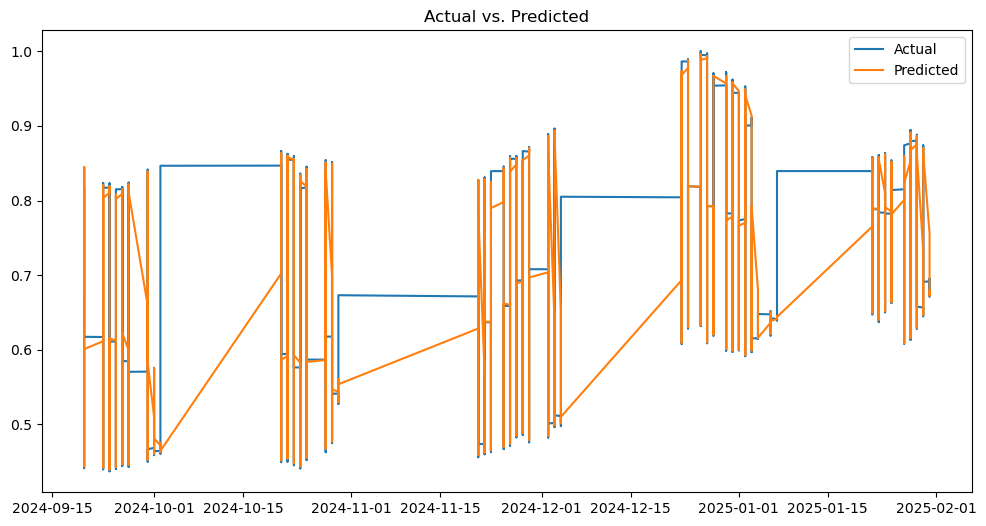

In [26]:
plt.figure(figsize=(12,6))
plt.plot(y_test.index, y_test, label='Actual')
plt.plot(y_test.index, y_pred, label='Predicted')
plt.legend(); plt.title("Actual vs. Predicted"); plt.show()


### LSTM model (GOOG, 60-minute look-back)

The next cells build sequences of the last 60 minutes for GOOG and define a two-layer LSTM. Training on ~470k sequences was too slow on our hardware within the block, so the training run was stopped before it finished and there are no LSTM results here.

In [23]:
SEQ_LEN = 60   # look back 60 minutes
features = [
    'open_value','high_value','low_value','close_value','return_pct',
    'intraday_volatility','volume','transactions',
    'index_open','index_close','index_high','index_low',
    'stock_market_volatility_vix_index','gdp_growth','inflation_cpi',
    'return_lag_5','low_rolling_mean_5','high_rolling_mean_5',
    'low_rolling_std_5','high_rolling_std_5','momentum_hl',
    'range_pct_hl','mid_price','rolling_range_5'
]


In [24]:
# filter for GOOG
df_t = df_scaled[df_scaled['company_prefix']=='GOOG'].copy()

# assemble array of features + target in last column
arr = df_t[features + ['high_value']].values

# scale per-ticker
scaler_t = MinMaxScaler()
arr = scaler_t.fit_transform(arr)

# build sequences
X, y = [], []
for i in range(len(arr) - SEQ_LEN):
    X.append(arr[i : i + SEQ_LEN, :-1])   # all cols except last
    y.append(arr[i + SEQ_LEN, -1])        # the target
X = np.array(X)
y = np.array(y)

# train/test split (80/20)
split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

print("GOOG:", X_train.shape, "train samples;", X_test.shape, "test samples")


GOOG: (471950, 60, 24) train samples; (117988, 60, 24) test samples


In [25]:
model = Sequential([
    LSTM(64, input_shape=(SEQ_LEN, X_train.shape[-1]), return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(1, activation='linear')
])
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 60, 64)            22784     
                                                                 
 dropout (Dropout)           (None, 60, 64)            0         
                                                                 
 lstm_1 (LSTM)               (None, 32)                12416     
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                                                 
 dense (Dense)               (None, 1)                 33        
                                                                 
Total params: 35,233
Trainable params: 35,233
Non-trainable params: 0
_________________________________________________________________


In [30]:
es = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=50,
    batch_size=128,
    callbacks=[es],
    verbose=2
)

Epoch 1/50


## ✅ Step 7: Backtesting (not finished)

We wrote a simple backtesting function: buy when the model predicts a higher price than the current one, sell at the next close. Connecting it to the model predictions on the test set was not finished, so the cells below have no results yet.

In [28]:
def backtest_strategy(df, prediction_col, price_col='close'):
    """
    Simulate a trading strategy:
    - Buy when model predicts the next day's price will be higher than today.
    - Sell at next day's actual close price.
    
    Parameters:
    - df: DataFrame with at least 'prediction_col' and 'close'
    - prediction_col: Column name with model predictions
    - price_col: Column with actual prices (default = 'close')
    
    Returns:
    - DataFrame with trades and performance metrics
    """
    df = df.copy()
    df['buy_signal'] = df[prediction_col] > df[price_col]
    df['next_close'] = df[price_col].shift(-1)

    df['position'] = df['buy_signal'].astype(int)
    df['strategy_return'] = df['position'] * (df['next_close'] - df[price_col])
    
    df['cumulative_return'] = df['strategy_return'].cumsum()
    return df


In [29]:
# Prepare a DataFrame for backtesting using test set
backtest_df = pd.DataFrame({
	'close': X_test['high'],  # using 'high' as a proxy for close since only high/low are present
	'predicted_high': y_pred_clean
}, index=X_test.index)

result = backtest_strategy(backtest_df, prediction_col='predicted_high', price_col='close')

# Plot performance
import matplotlib.pyplot as plt
plt.plot(result['cumulative_return'], label='Strategy')
plt.title('Cumulative Return')
plt.legend()
plt.show()


In [ ]:
total_return = result['strategy_return'].sum()
num_trades = result['position'].sum()
avg_return_per_trade = result['strategy_return'][result['position'] == 1].mean()

print(f"Total return: {total_return:.2f}")
print(f"Number of trades: {num_trades}")
print(f"Average return per trade: {avg_return_per_trade:.2f}")


## 🚀 Next steps

These parts of the original plan were not finished within the block:

- **Fix the evaluation setup.** Split train/test per company and fit the scaler only on the training data to avoid look-ahead leakage. Compare against a naïve "next value = current value" baseline, which is very strong for minute data.
- **Finish the LSTM.** Train on a smaller sample or on a GPU, then compare it with the linear baseline.
- **Hyperparameter tuning.** Use time-series cross-validation (`TimeSeriesSplit`) with grid or random search.
- **Backtesting.** Run the strategy function on out-of-sample predictions and include transaction costs.
- **Results table and deployment.** Write predictions back to the warehouse and save the final model for a dashboard or alert service.